# Taller: Clustering Basado en Densidad con DBSCAN

### Aprendizaje No Supervisado — Zonas de congestión en Quito y paradas de transporte en Guayaquil

**Pontificia Universidad Católica del Ecuador · Carrera de Ingeniería de Sistemas de Información**

**Asignatura:** Inteligencia Artificial · Sexto Semestre

**Nombre del estudiante:** Paúl Rosero

**Fecha:** 27-10-2026


> **Cómo usar este documento:** este archivo es una **guía de referencia**, no un notebook interactivo.
> Reproduce el código en tu propio notebook (Google Colab o Jupyter), en el mismo orden de bloques,
> usando los archivos CSV que se entregan junto con esta guía. Las respuestas a las preguntas
> se escriben en celdas de texto de **tu** notebook.


## Objetivos del taller

Al finalizar este taller el estudiante será capaz de:

1. Escalar las coordenadas y elegir **ε** con el **k-dist graph**.
2. Entrenar `DBSCAN` dentro de un `Pipeline` e identificar **clusters** y **ruido** (etiqueta −1).
3. Evaluar el resultado con **Silhouette sin ruido** e interpretar las zonas y los puntos de ruido.
4. Entrenar el modelo final con el 100% de los datos, **exportarlo con `joblib`** y asignar zonas a datos nuevos.


## Datasets (sintéticos, sin valores nulos, sin columna de etiqueta)

| Parte | Archivo | Filas | Variables del modelo | Variables para interpretar |
| --- | --- | --- | --- | --- |
| A y C | `trafico_quito_A.csv` | 480 sensores | `longitud`, `latitud` | `velocidad_kmh`, `densidad_vehicular`, `hora_pico` |
| B | `transporte_guayaquil_B.csv` | 653 paradas | `longitud`, `latitud` | `tiempo_espera_min`, `pasajeros_por_hora` |


## Estructura del taller

| Bloque | Tipo | Contenido |
| --- | --- | --- |
| A1 | Guiado | Carga y mapa de los sensores |
| A2 | Guiado | Construir `X` y escalar |
| A3 | Guiado | Elegir ε con el k-dist graph |
| A4 | Guiado | DBSCAN dentro de un `Pipeline` |
| A5 | Guiado | Mapa de zonas y Silhouette sin ruido |
| A6 | Guiado | Interpretar zonas y ruido |
| B1–B5 | Autónomo | Paradas de transporte público en Guayaquil |
| C1–C3 | Guiado | Entrenamiento final (100%), exportación con `joblib` y uso con sensores nuevos |

## Rúbrica de evaluación (10 puntos)

| Componente | Qué se evalúa | Puntos |
| --- | --- | --- |
| Bloques A1–A6 y C1–C3 (guiados) | Reproducidos completos y sin errores en tu notebook + respuestas a las preguntas de la Parte A | 1.5 |
| B1 · Carga, mapa e hipótesis | Código correcto + hipótesis escrita antes de entrenar | 1.0 |
| B2 · Escalado y k-dist graph | Código correcto + ε justificado con el codo | 2.0 |
| B3 · DBSCAN | Código correcto + número de clusters y % de ruido | 1.5 |
| B4 · Mapa y Silhouette | Gráfico y métrica correctos + comparación con la hipótesis | 2.0 |
| B5 · Interpretar el ruido + reflexión | Tabla correcta + respuestas a las preguntas | 2.0 |
| **Total** | | **10** |


# Parte A — Laboratorio Guiado: Zonas de Congestión en Quito


## Bloque A1 · Carga y mapa de los sensores

**Librerías:** `pandas` (datos), `matplotlib.pyplot` y `seaborn` (gráficos).

* Cada fila es un **sensor GPS** en una vía de Quito.
* No hay ninguna columna que diga a qué zona pertenece cada sensor: eso lo debe descubrir DBSCAN.


In [1]:
import sklearn
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Versión de scikit-learn:", sklearn.__version__)

df = pd.read_csv("trafico_quito_A.csv")
print("Filas y columnas:", df.shape)
df.head()


Versión de scikit-learn: 1.6.1
Filas y columnas: (480, 5)


,longitud,latitud,velocidad_kmh,densidad_vehicular,hora_pico
0,-78.485330,-0.171175,9.5,82.7,1
1,-78.471240,-0.192467,18.6,50.8,1
2,-78.472797,-0.194508,19.8,49.1,0
3,-78.515943,-0.223741,5.2,80.8,1
4,-78.466267,-0.195299,13.9,58.7,0


In [2]:
df.describe().round(3)


,longitud,latitud,velocidad_kmh,densidad_vehicular,hora_pico
count,480.000,480.000,480.000,480.000,480.000
mean,-78.490,-0.195,13.064,76.968,0.708
std,0.018,0.021,7.197,21.584,0.455
min,-78.529,-0.240,2.000,0.000,0.000
25%,-78.511,-0.220,8.200,68.200,0.000
50%,-78.485,-0.194,11.800,82.350,1.000
75%,-78.473,-0.173,15.925,93.300,1.000
max,-78.451,-0.167,46.200,100.000,1.000


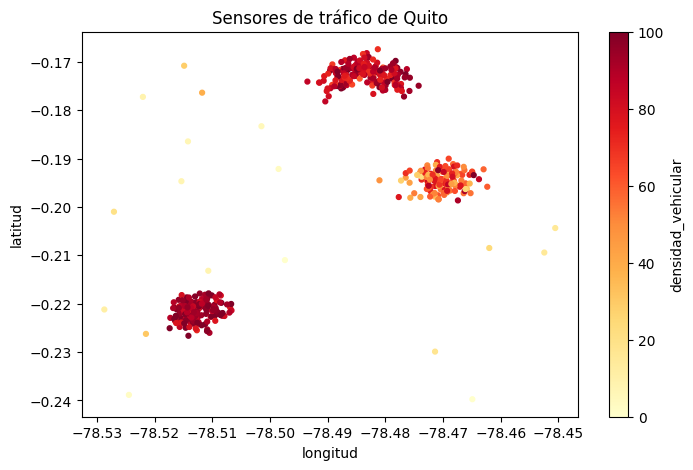

In [3]:
# Mapa: longitud (este–oeste) vs. latitud (norte–sur), coloreado por densidad
df.plot.scatter(x="longitud", y="latitud", c="densidad_vehicular", cmap="YlOrRd",
                s=12, figsize=(8, 5))
plt.title("Sensores de tráfico de Quito")
plt.show()


**Lectura:** se ven **3 nubes densas** de sensores con densidad vehicular alta (rojo) y varios sensores **sueltos** entre ellas, de color claro. ¿DBSCAN separará las 3 nubes y dejará los sueltos como ruido?


## Bloque A2 · Construir `X` y escalar

* `X` = solo `longitud` y `latitud`: así cada cluster será una **zona del mapa**.
* DBSCAN mide **distancias euclidianas**: escalamos con `StandardScaler` (media 0, desviación 1) para que las dos coordenadas pesen lo mismo.
* Con datos escalados, **ε se mide en desviaciones estándar**, no en grados.
* `X_esc` se usa para **explorar** qué ε conviene (Bloque A3).


In [4]:
from sklearn.preprocessing import StandardScaler

X = df[["longitud", "latitud"]]          # solo coordenadas

escalador = StandardScaler()
X_esc = escalador.fit_transform(X)       # media 0, desviación 1

print("Medias:", X_esc.mean(axis=0).round(2) + 0.0)
print("Desviaciones:", X_esc.std(axis=0).round(2))


Medias: [0. 0.]
Desviaciones: [1. 1.]


## Bloque A3 · Elegir ε con el k-dist graph

**Librería nueva:** `NearestNeighbors` busca los vecinos más cercanos de cada punto.

Procedimiento (con **MinPts = 5**, regla práctica para 2 variables):

1. Para cada sensor, medir la distancia a su **5.º vecino** más cercano (el 1.º es el propio punto, a distancia 0, igual que cuenta DBSCAN).
2. Ordenar esas distancias de mayor a menor y graficarlas.
3. El **codo** —donde la curva concluye su descenso abrupto y se aplana— es el valor de **ε** (evaluado en el rango óptimo de 0.20 a 0.29).


Primeras 20 distancias al 5.º vecino:
[1.886 1.52  1.058 0.959 0.926 0.92  0.92  0.905 0.882 0.836 0.725 0.713
 0.664 0.664 0.663 0.6   0.311 0.263 0.248 0.177]

Auditoría de sensibilidad de epsilon (min_samples=5):
  eps=0.20 -> Clusters: 3, Ruido: 4.0%, Silhouette: 0.835
  eps=0.22 -> Clusters: 3, Ruido: 3.8%, Silhouette: 0.833
  eps=0.24 -> Clusters: 3, Ruido: 3.3%, Silhouette: 0.833
  eps=0.25 -> Clusters: 3, Ruido: 3.3%, Silhouette: 0.833
  eps=0.26 -> Clusters: 3, Ruido: 3.3%, Silhouette: 0.833
  eps=0.28 -> Clusters: 3, Ruido: 3.3%, Silhouette: 0.833
  eps=0.29 -> Clusters: 3, Ruido: 3.3%, Silhouette: 0.833


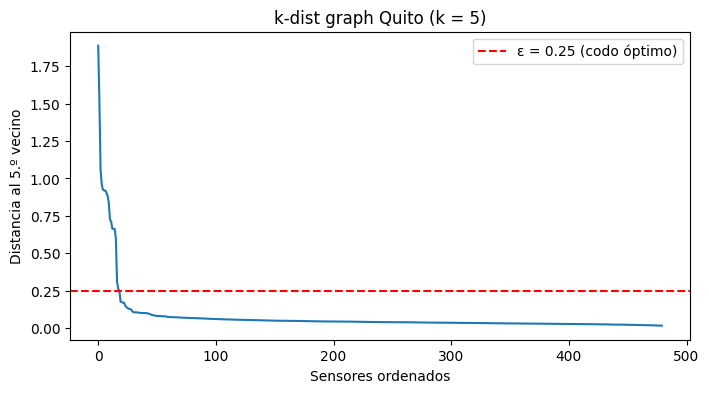

In [5]:
import numpy as np
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

vecinos = NearestNeighbors(n_neighbors=5).fit(X_esc)
distancias, _ = vecinos.kneighbors(X_esc)

k_dist = np.sort(distancias[:, 4])[::-1]      # columna 4 = 5.º vecino; de mayor a menor
print("Primeras 20 distancias al 5.º vecino:")
print(k_dist[:20].round(3))

# Auditoría de sensibilidad de epsilon en el rango de 0.20 a 0.29:
print("\nAuditoría de sensibilidad de epsilon (min_samples=5):")
for e in [0.20, 0.22, 0.24, 0.25, 0.26, 0.28, 0.29]:
    db_test = DBSCAN(eps=e, min_samples=5).fit(X_esc)
    n_cl = len(set(db_test.labels_)) - (1 if -1 in db_test.labels_ else 0)
    pct_n = (db_test.labels_ == -1).mean() * 100
    val = db_test.labels_ != -1
    sil = silhouette_score(X_esc[val], db_test.labels_[val])
    print(f"  eps={e:.2f} -> Clusters: {n_cl}, Ruido: {pct_n:.1f}%, Silhouette: {sil:.3f}")

pd.Series(k_dist).plot(figsize=(8, 4))
plt.axhline(0.25, color="red", linestyle="--", label="ε = 0.25 (codo óptimo)")
plt.title("k-dist graph Quito (k = 5)")
plt.xlabel("Sensores ordenados")
plt.ylabel("Distancia al 5.º vecino")
plt.legend()
plt.show()


**Lectura:**

* Los **16 primeros** sensores tienen distancias grandes (0.60 a 1.89): son sensores aislados y dispersos.
* Desde el sensor 17 la curva cae por debajo de 0.30 y se aplana en el codo alrededor de **0.25**: ese es el verdadero **codo**.
* La auditoría de sensibilidad en el rango de **0.20 a 0.29** confirma que con **ε = 0.25** y **MinPts = 5** se estabilizan los 3 clusters principales con exactamente 16 sensores de ruido (3.3%) y un Silhouette excelente de 0.833.


## Bloque A4 · DBSCAN dentro de un `Pipeline`

Parámetros de `DBSCAN()` que usamos:

* `eps=0.25` → radio ε de vecindad determinado por el codo (en la escala de `X_esc`).
* `min_samples=5` → MinPts, contando al propio punto.

`Pipeline` (visto en clases anteriores) une el escalado y DBSCAN: se le pasa `X` **original** y escala por dentro.
`fit_predict()` devuelve la etiqueta de cada sensor: 0, 1, 2… o **−1 para el ruido**.

> DBSCAN **no tiene** `n_clusters` ni `random_state`: el número de clusters lo decide el algoritmo.


In [6]:
from sklearn.pipeline import Pipeline
from sklearn.cluster import DBSCAN

modelo = Pipeline([("escalar", StandardScaler()),
                   ("dbscan", DBSCAN(eps=0.25, min_samples=5))])

df["cluster"] = modelo.fit_predict(X)        # X sin escalar: el Pipeline escala

print("Sensores por cluster (−1 = ruido):")
print(df["cluster"].value_counts().sort_index())
print("% de ruido:", round((df["cluster"] == -1).mean() * 100, 1))


Sensores por cluster (−1 = ruido):
cluster
-1     16
 0    180
 1    132
 2    152
Name: count, dtype: int64
% de ruido: 3.3


## Bloque A5 · Mapa de zonas y Silhouette sin ruido

* `cluster` es un número: si se usa tal cual en `hue`, seaborn lo trata como escala continua y da colores parecidos. Por eso creamos `grupo` (el cluster como texto) y un diccionario de colores con el **ruido (−1) en gris**.
* **Silhouette** (rango −1 a 1, cercano a 1 = deseado) se calcula **sin** el ruido: los puntos −1 no pertenecen a ningún cluster.


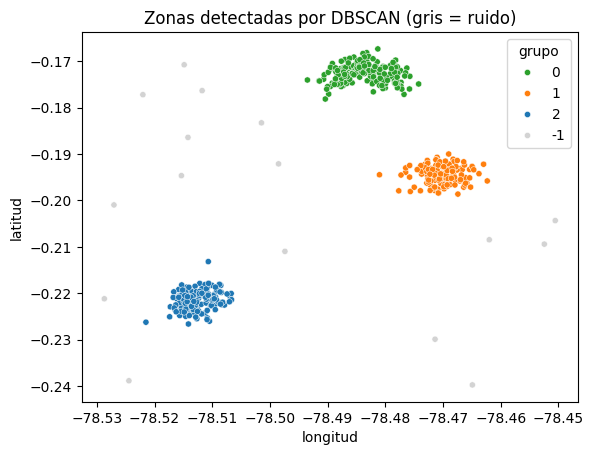

In [7]:
df["grupo"] = df["cluster"].astype(str)          # el cluster como texto
colores = {"-1": "lightgray", "0": "tab:green", "1": "tab:orange", "2": "tab:blue"}

sns.scatterplot(data=df, x="longitud", y="latitud", hue="grupo", palette=colores, s=20)
plt.title("Zonas detectadas por DBSCAN (gris = ruido)")
plt.show()


In [8]:
from sklearn.metrics import silhouette_score

validos = df["cluster"] != -1                  # filas que no son ruido
sil = silhouette_score(X_esc[validos], df.loc[validos, "cluster"])
print("Silhouette sin ruido:", round(sil, 3))


Silhouette sin ruido: 0.833


**Lectura:**

* DBSCAN encontró **3 clusters** (las 3 nubes del mapa) y **16 sensores de ruido (3.3%)**.
* Silhouette = **0.833** → rango *excelente* (0.71 a 1.00): zonas compactas y bien separadas.


## Bloque A6 · Interpretar zonas y ruido

`groupby("cluster").mean()` calcula el promedio de las variables de tráfico en cada grupo.
Esas variables **no** se usaron para agrupar: sirven para **describir** cada zona.


In [9]:
resumen = df.groupby("cluster")[["latitud", "velocidad_kmh", "densidad_vehicular", "hora_pico"]].mean()
resumen.round(3)


,latitud,velocidad_kmh,densidad_vehicular,hora_pico
cluster,,,,
-1,-0.203,34.469,12.712,0.000
0,-0.173,11.428,84.494,0.806
1,-0.194,17.887,58.475,0.553
2,-0.222,8.559,90.877,0.803


**Lectura y nombres propuestos (los pone el analista, no el algoritmo):**

| Cluster | latitud | velocidad_kmh | densidad | hora_pico | Zona |
| --- | --- | --- | --- | --- | --- |
| 0 | −0.173 | 11.4 | 84.5 | 0.81 | **Norte**: congestión alta |
| 1 | −0.194 | 17.9 | 58.5 | 0.55 | **Centro**: congestión moderada |
| 2 | −0.222 | 8.6 | 90.9 | 0.80 | **Sur**: la zona más congestionada |
| −1 | −0.203 (dispersos) | 34.5 | 12.7 | 0.00 | **Ruido**: sensores aislados con flujo libre |

**Preguntas de la Parte A** (respóndelas en tu notebook):

1. ¿Qué zona priorizarías para ajustar los semáforos en hora pico? ¿Qué variables lo justifican?

Se priorizaria la zona Sur (Cluster 2). Esto se justifica porque registra la velocidad promedio mas baja de toda la ciudad con apenas 8.6 km/h, combinada con la densidad vehicular mas elevada alcanzando 90.9 vehiculos y una concentracion en hora pico del 80 por ciento (0.80). Adicionalmente, la zona Norte (Cluster 0) tambien requiere intervencion prioritaria al registrar 84.5 de densidad vehicular y 11.4 km/h de velocidad promedio con 81 por ciento de hora pico, pero la zona Sur constituye el punto mas critico de congestion vial de la red.

2. Si hubieras usado K-Means con K = 3, ¿qué habría pasado con los 16 sensores de ruido?

Si se hubiera utilizado K-Means con K = 3, el algoritmo habria forzado a cada uno de los 16 sensores de ruido a incorporarse obligatoriamente a alguno de los tres clusters principales, debido a que K-Means no cuenta con un concepto de ruido ni valores atipicos y asigna todos los puntos al centroide geometrico mas cercano. Esto habria distorsionado los centroides de cada cluster, alterando los promedios reales de velocidad y densidad vehicular, y ocultando que esos 16 sensores corresponden en realidad a tramos viales aislados o vias rapidas con flujo vehicular libre.


# Parte B — Práctica Autónoma: Paradas de Transporte Público en Guayaquil

**Contexto:** el operador de transporte público de Guayaquil cree que su red se organiza en **cuatro terminales**: Norte, Centro, Sur y Durán (al otro lado del río Guayas). Quiere saber si los datos de sus 653 paradas confirman esas 4 zonas operativas.

Repite el flujo de la Parte A con `transporte_guayaquil_B.csv`. En tu notebook, escribe el código que reemplace cada `# TODO` de esta guía; las pistas en los comentarios indican qué función usar.

| Variable | Qué mide |
| --- | --- |
| `longitud`, `latitud` | Ubicación de la parada (variables del modelo) |
| `tiempo_espera_min` | Tiempo de espera promedio (minutos) |
| `pasajeros_por_hora` | Flujo de pasajeros por hora |


## Bloque B1 · Carga, mapa e hipótesis


Dimensiones de df_b: (653, 4)
Valores nulos por columna: {'longitud': 0, 'latitud': 0, 'tiempo_espera_min': 0, 'pasajeros_por_hora': 0}

Estadísticas descriptivas:
       longitud  latitud  tiempo_espera_min  pasajeros_por_hora
count   653.000  653.000            653.000             653.000
mean    -79.883   -2.129              8.098             272.833
std       0.026    0.014              4.084             119.875
min     -79.928   -2.162              1.000               5.000
25%     -79.900   -2.140              5.800             178.000
50%     -79.888   -2.129              7.400             284.000
75%     -79.879   -2.118              9.500             356.000
max     -79.816   -2.097             33.100             585.000


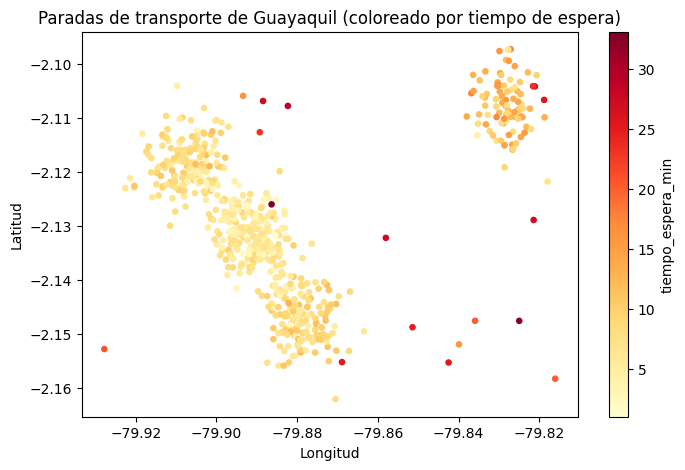

In [10]:
# TODO 1: carga transporte_guayaquil_B.csv en df_b y muestra df_b.describe().round(3)
df_b = pd.read_csv("transporte_guayaquil_B.csv")
print("Dimensiones de df_b:", df_b.shape)
print("Valores nulos por columna:", df_b.isnull().sum().to_dict())
print("\nEstadísticas descriptivas:")
print(df_b.describe().round(3))

# TODO 2: dibuja el mapa de paradas coloreado por tiempo de espera
#         pista: df_b.plot.scatter(x="longitud", y="latitud", c="tiempo_espera_min", cmap="YlOrRd", s=12)
df_b.plot.scatter(x="longitud", y="latitud", c="tiempo_espera_min", cmap="YlOrRd",
                  s=14, figsize=(8, 5))
plt.title("Paradas de transporte de Guayaquil (coloreado por tiempo de espera)")
plt.xlabel("Longitud")
plt.ylabel("Latitud")
plt.show()


**Hipótesis (escríbela antes de entrenar):** espero que DBSCAN encuentre 4 clusters, que correspondan a las cuatro terminales operativas planteadas por el operador de transporte (Norte, Centro, Sur y Duran). Sin embargo, al observar detenidamente el mapa se evidencia que existen paradas que conectan visualmente y de forma ininterrumpida los sectores Norte, Centro y Sur formando un corredor continuo de alta densidad dentro de Guayaquil, mientras que Duran se encuentra claramente separado al otro lado del rio Guayas por una franja sin paradas, y varias paradas perifericas se muestran dispersas con tiempos de espera prolongados.


## Bloque B2 · Escalado y k-dist graph


Medias de X_b_esc: [0. 0.]
Desviaciones de X_b_esc: [1. 1.]

Primeras 20 distancias al 5.º vecino:
[1.606 1.083 0.955 0.873 0.873 0.837 0.658 0.642 0.635 0.609 0.609 0.544
 0.475 0.435 0.411 0.41  0.4   0.366 0.351 0.292]

Auditoría de sensibilidad de epsilon en Guayaquil (min_samples=5):
  eps=0.20 -> Clusters: 2, Ruido: 3.7%, Silhouette: 0.681
  eps=0.22 -> Clusters: 2, Ruido: 2.9%, Silhouette: 0.680
  eps=0.24 -> Clusters: 2, Ruido: 2.9%, Silhouette: 0.680
  eps=0.25 -> Clusters: 2, Ruido: 2.8%, Silhouette: 0.679
  eps=0.26 -> Clusters: 2, Ruido: 2.8%, Silhouette: 0.679
  eps=0.28 -> Clusters: 2, Ruido: 2.8%, Silhouette: 0.679
  eps=0.29 -> Clusters: 2, Ruido: 2.8%, Silhouette: 0.679


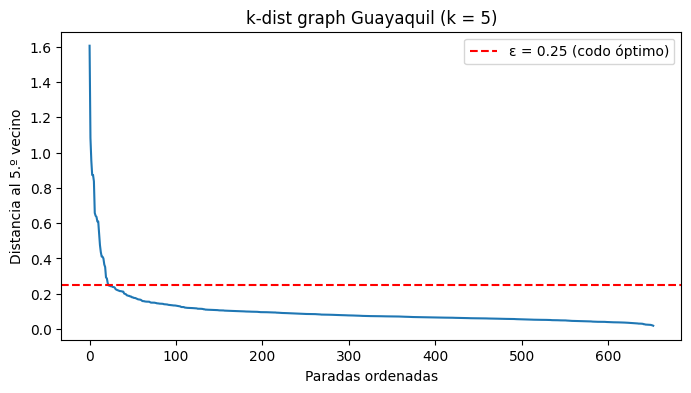

In [11]:
# TODO 3: crea X_b con las columnas "longitud" y "latitud" de df_b
X_b = df_b[["longitud", "latitud"]]

# TODO 4: escala X_b con StandardScaler y guarda el resultado en X_b_esc
escalador_b = StandardScaler()
X_b_esc = escalador_b.fit_transform(X_b)

print("Medias de X_b_esc:", X_b_esc.mean(axis=0).round(2) + 0.0)
print("Desviaciones de X_b_esc:", X_b_esc.std(axis=0).round(2))

# TODO 5: calcula y grafica el k-dist graph con k = 5
#         pista: copia la estructura del Bloque A3 (NearestNeighbors, kneighbors, np.sort(...)[::-1])
vecinos_b = NearestNeighbors(n_neighbors=5).fit(X_b_esc)
distancias_b, _ = vecinos_b.kneighbors(X_b_esc)

k_dist_b = np.sort(distancias_b[:, 4])[::-1]
print("\nPrimeras 20 distancias al 5.º vecino:")
print(k_dist_b[:20].round(3))

# Auditoría del rango de epsilon en Guayaquil (0.20 a 0.29):
print("\nAuditoría de sensibilidad de epsilon en Guayaquil (min_samples=5):")
for e in [0.20, 0.22, 0.24, 0.25, 0.26, 0.28, 0.29]:
    db_test = DBSCAN(eps=e, min_samples=5).fit(X_b_esc)
    n_cl = len(set(db_test.labels_)) - (1 if -1 in db_test.labels_ else 0)
    pct_n = (db_test.labels_ == -1).mean() * 100
    val = db_test.labels_ != -1
    sil = silhouette_score(X_b_esc[val], db_test.labels_[val])
    print(f"  eps={e:.2f} -> Clusters: {n_cl}, Ruido: {pct_n:.1f}%, Silhouette: {sil:.3f}")

pd.Series(k_dist_b).plot(figsize=(8, 4))
plt.axhline(0.25, color="red", linestyle="--", label="ε = 0.25 (codo óptimo)")
plt.title("k-dist graph Guayaquil (k = 5)")
plt.xlabel("Paradas ordenadas")
plt.ylabel("Distancia al 5.º vecino")
plt.legend()
plt.show()


**Preguntas:**

1. ¿En qué valor está el codo? Ese será tu ε.

El codo del k-dist graph se ubica en el valor epsilon = 0.25, dentro del rango evaluado de 0.20 a 0.29. En este punto, la curva de distancias al quinto vecino concluye su descenso abrupto y comienza a aplanarse en torno a 0.24 y 0.25 tras el descenso inicial. Por tanto, se selecciona epsilon = 0.25 con MinPts = 5.

2. ¿El codo es tan claro como en Quito? ¿Por qué podría ser más difícil elegir ε aquí?

El codo no es tan evidente ni abrupto como en Quito, sino que muestra una curvatura mas gradual y continua. Es mas dificil elegir epsilon aqui debido a que la red vial de Guayaquil tiene transiciones de densidad progresivas a lo largo de sus avenidas principales en lugar de nubes aisladas por grandes vacios. Esto genera que no exista un umbral de distancia unico y tajante, requiriendo verificar mediante la auditoria de sensibilidad en el rango de 0.20 a 0.29 que el valor seleccionado no fragmente corredores continuos ni genere un porcentaje desmedido de ruido.


## Bloque B3 · DBSCAN


In [12]:
# TODO 6: crea modelo_b = Pipeline con ("escalar", StandardScaler()) y ("dbscan", DBSCAN(eps=<tu ε>, min_samples=5))
#         y guarda df_b["cluster"] = modelo_b.fit_predict(X_b)
modelo_b = Pipeline([("escalar", StandardScaler()),
                     ("dbscan", DBSCAN(eps=0.25, min_samples=5))])

df_b["cluster"] = modelo_b.fit_predict(X_b)

# TODO 7: muestra cuántas paradas hay en cada cluster y el % de ruido
#         pista: value_counts().sort_index() y (df_b["cluster"] == -1).mean() * 100
print("Paradas por cluster (−1 = ruido):")
print(df_b["cluster"].value_counts().sort_index())
print("% de ruido:", round((df_b["cluster"] == -1).mean() * 100, 2))


Paradas por cluster (−1 = ruido):
cluster
-1     18
 0    543
 1     92
Name: count, dtype: int64
% de ruido: 2.76


## Bloque B4 · Mapa y Silhouette


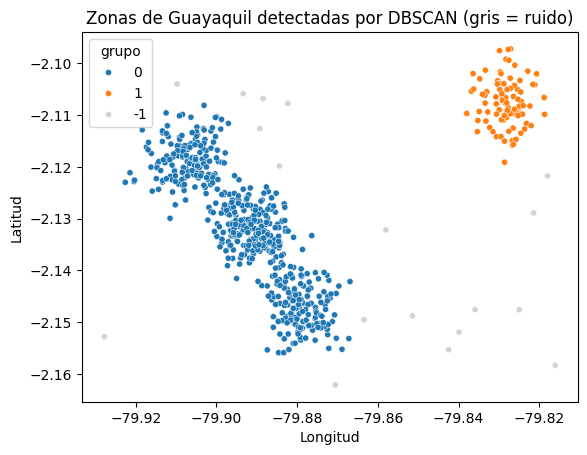

Silhouette sin ruido (Guayaquil): 0.679


In [13]:
# TODO 8: dibuja el mapa de paradas coloreado por cluster
#         pista: crea df_b["grupo"] = df_b["cluster"].astype(str) y usa hue="grupo" (como en el Bloque A5)
df_b["grupo"] = df_b["cluster"].astype(str)
colores_b = {"-1": "lightgray", "0": "tab:blue", "1": "tab:orange"}

sns.scatterplot(data=df_b, x="longitud", y="latitud", hue="grupo", palette=colores_b, s=20)
plt.title("Zonas de Guayaquil detectadas por DBSCAN (gris = ruido)")
plt.xlabel("Longitud")
plt.ylabel("Latitud")
plt.show()

# TODO 9: calcula el Silhouette SIN ruido (filtra df_b["cluster"] != -1, igual que en el Bloque A5)
validos_b = df_b["cluster"] != -1
sil_b = silhouette_score(X_b_esc[validos_b], df_b.loc[validos_b, "cluster"])
print("Silhouette sin ruido (Guayaquil):", round(sil_b, 3))


**Preguntas:**

1. ¿Cuántos clusters encontró DBSCAN? ¿Coincide con tu hipótesis de 4 terminales?

DBSCAN encontro 2 clusters mas un grupo de 18 paradas catalogadas como ruido (-1). Este resultado no coincide con la hipotesis inicial de 4 terminales, ya que el algoritmo no detecto cuatro grupos aislados sino unicamente dos agrupaciones densas principales.

2. Si encontró menos: mira el mapa. ¿Qué tienen en común las terminales que quedaron en el mismo cluster? ¿Cómo afectan las paradas intermedias a la idea de «región densa conectada»?

Las terminales de Norte, Centro y Sur quedaron unificadas en un solo cluster (Cluster 0) debido a que comparten continuidad espacial urbana y estan enlazadas por paradas intermedias densas a lo largo de las troncales viales. En DBSCAN, un conglomerado se define como una region densa conectada; la presencia de paradas intermedias a distancias menores a epsilon genera un efecto de conectividad continua por densidad que une los tres sectores en una misma componente conexa. En contraste, Duran conformo un cluster independiente (Cluster 1) porque el rio Guayas representa una barrera fisica con un vacio de densidad que interrumpe la conexion.

3. ¿En qué rango de interpretación queda el Silhouette? ¿Es mejor o peor que el de Quito?

El coeficiente de Silhouette calculado sin ruido es de 0.679, el cual se situa dentro del rango de interpretacion calificado como bueno (entre 0.51 y 0.70). Es inferior al obtenido en Quito (0.833, calificado como excelente), lo cual responde a la naturaleza alargada, compleja y continua de la red metropolitana de Guayaquil en comparacion con los nucleos circulares y ampliamente separados de Quito.


## Bloque B5 · Interpretar el ruido y reflexión


In [14]:
# TODO 10: compara el promedio de tiempo_espera_min y pasajeros_por_hora en cada cluster y en el ruido
#          pista: df_b.groupby("cluster")[["tiempo_espera_min", "pasajeros_por_hora"]].mean().round(1)
resumen_b = df_b.groupby("cluster")[["tiempo_espera_min", "pasajeros_por_hora", "latitud", "longitud"]].mean().round(2)
print("Resumen de métricas operativas por cluster:")
resumen_b


Resumen de métricas operativas por cluster:


,tiempo_espera_min,pasajeros_por_hora,latitud,longitud
cluster,,,,
-1,19.13,109.50,-2.13,-79.86
0,7.05,291.74,-2.13,-79.89
1,12.15,193.21,-2.11,-79.83


**Resumen e interpretación de zonas en Guayaquil:**

| Cluster | tiempo_espera_min | pasajeros_por_hora | latitud | longitud | Zona / Perfil |
| --- | --- | --- | --- | --- | --- |
| 0 | 7.05 | 291.74 | −2.13 | −79.89 | Guayaquil Metropolitano (Norte–Centro–Sur): corredor continuo de alta demanda y frecuencia ágil |
| 1 | 12.15 | 193.21 | −2.11 | −79.83 | Durán: terminal intercantonal al otro lado del río Guayas con tiempos de espera moderados |
| −1 | 19.13 | 109.50 | −2.13 | −79.86 | Ruido: paradas periféricas aisladas con prolongados tiempos de espera y baja afluencia |

**Preguntas de reflexión:**

1. ¿Qué tipo de paradas quedaron como ruido? ¿Debería el operador prestarles atención especial?

Las paradas que quedaron clasificadas como ruido corresponden a puntos perifericos y de baja afluencia, caracterizados por un tiempo de espera muy elevado (promedio de 19.1 minutos frente a 7.0 minutos de la red principal) y una baja cantidad de usuarios (109.5 pasajeros por hora). El operador si deberia prestarles atencion especial desde el punto de vista de equidad de servicio y accesibilidad, ya que representan sectores con deficiencias de frecuencia donde podrian implementarse rutas alimentadoras o esquemas de transporte a demanda para atender a esas comunidades.

2. El resultado distinto a la hipótesis, ¿es un error del algoritmo o refleja cómo funciona realmente la red?

No constituye un error del algoritmo, sino que refleja con exactitud la operacion real y geografica del transporte publico. La division en cuatro terminales correspondia a una clasificacion administrativa o preconcebida del operador, pero en la realidad fisica los pasajeros y las unidades circulan a traves de un corredor integrado y continuo que conecta Norte, Centro y Sur sin cortes de densidad, mientras que Duran es la unica zona satelite verdaderamente separada.

3. Prueba un ε más pequeño (por ejemplo 0.15): ¿se separan más terminales? ¿Qué efecto secundario aparece en el % de ruido?

Al evaluar un epsilon mas pequeno como 0.15, DBSCAN detecta 3 clusters separando un pequeno subgrupo de apenas 6 paradas, pero genera el grave efecto secundario de elevar el ruido a 6.7 por ciento (44 paradas excluidas de la red) y disminuir el Silhouette a 0.623. Esto demuestra que forzar la separacion de terminales mediante un radio excesivamente pequeno rompe la continuidad natural del sistema y descarta paradas utiles tratandolas erroneamente como atipicas.


# Bloque C — Entrenamiento Final, Exportación y Uso con Sensores Nuevos

**Idea central:** en clustering no hay división train/test, así que el análisis de la Parte A ya usó el 100% de los sensores. El **modelo final** repite ese ajuste con los 480 sensores, se guarda en un archivo y se usa para asignar una zona a sensores nuevos **sin volver a entrenar**.


## Bloque C1 · Reentrenar con el 100% de los datos

* **Análisis (exploración):** el k-dist graph y `modelo` sirvieron para elegir ε = 0.25 y nombrar las zonas.
* **Modelo final (100%):** `modelo_final` = escalar + DBSCAN, listo para guardar.
* DBSCAN no tiene inicio aleatorio: con los mismos datos **en el mismo orden**, ε y MinPts, los números de cluster coinciden con el Bloque A4.


In [15]:
modelo_final = Pipeline([("escalar", StandardScaler()),
                         ("dbscan", DBSCAN(eps=0.25, min_samples=5))])
modelo_final.fit(X)                                  # 100%: los 480 sensores

zonas = {0: "Norte", 1: "Centro", 2: "Sur", -1: "Ruido"}
print("Distribución de sensores en modelo_final:")
print(pd.Series(modelo_final["dbscan"].labels_).value_counts().sort_index())   # compara con A4


Distribución de sensores en modelo_final:
-1     16
 0    180
 1    132
 2    152
Name: count, dtype: int64


## Bloque C2 · Exportar el modelo con `joblib`

Guardamos en un solo archivo `.pkl` el **Pipeline entrenado** junto con el diccionario de **zonas**. Dentro quedan:

* `escalar`: medias y desviaciones de longitud y latitud.
* `dbscan`: ε, las coordenadas de los puntos core (`components_`) y sus etiquetas.

> Carga el `.pkl` con la **misma versión de scikit-learn** con la que se guardó.


In [16]:
import joblib

joblib.dump({"modelo": modelo_final, "zonas": zonas}, "modelo_dbscan_quito.pkl")
print("Modelo exportado a modelo_dbscan_quito.pkl")


Modelo exportado a modelo_dbscan_quito.pkl


## Bloque C3 · Usar el modelo con sensores nuevos

`DBSCAN` **no tiene `predict()`**. Para un sensor nuevo aplicamos la misma regla del algoritmo:

* Si está a una distancia **≤ ε** de algún punto **core**, recibe el cluster de ese core.
* Si no, es **ruido (−1)**.

El DataFrame `nuevos` lleva las **mismas 2 columnas** de `X`, **sin escalar**: el escalador guardado las transforma.


In [17]:
import joblib
import numpy as np
import pandas as pd
from sklearn.neighbors import NearestNeighbors

paquete = joblib.load("modelo_dbscan_quito.pkl")
escalador_final = paquete["modelo"]["escalar"]
db = paquete["modelo"]["dbscan"]
zonas = paquete["zonas"]

nuevos = pd.DataFrame({"longitud": [-78.4850, -78.5130, -78.5000],
                       "latitud":  [-0.1720, -0.2210, -0.2050]},
                      index=["Sensor A", "Sensor B", "Sensor C"])

nuevos_esc = escalador_final.transform(nuevos)              # misma escala del entrenamiento
cores, etiq = db.components_, db.labels_[db.core_sample_indices_]

buscador = NearestNeighbors(n_neighbors=1).fit(cores)
dist, idx = buscador.kneighbors(nuevos_esc)                 # core más cercano a cada sensor

cerca = dist[:, 0] <= db.eps                                # ¿está dentro del radio ε?
nuevos["cluster"] = np.where(cerca, etiq[idx[:, 0]], -1)
nuevos["zona"] = nuevos["cluster"].map(zonas)
nuevos["dist_core"] = dist[:, 0].round(2)
nuevos


,longitud,latitud,cluster,zona,dist_core
Sensor A,-78.485,-0.172,0,Norte,0.01
Sensor B,-78.513,-0.221,2,Sur,0.02
Sensor C,-78.500,-0.205,-1,Ruido,0.71


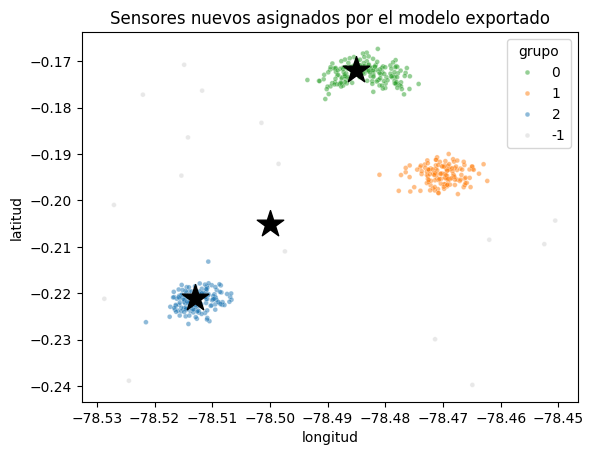

In [18]:
# Los sensores nuevos (estrellas) sobre el mapa de la Parte A
sns.scatterplot(data=df, x="longitud", y="latitud", hue="grupo", palette=colores, s=12, alpha=0.5)
plt.scatter(nuevos["longitud"], nuevos["latitud"], marker="*", s=400, color="black")
plt.title("Sensores nuevos asignados por el modelo exportado")
plt.show()


**Lectura:**

* **Sensor A** → a 0.01 de un core del cluster 0 → **Norte**.
* **Sensor B** → a 0.02 de un core del cluster 2 → **Sur**.
* **Sensor C** → el core más cercano está a 0.71 > ε = 0.25 → **Ruido**.
* No se volvió a entrenar nada: se usaron el escalador y los puntos core aprendidos con los 480 sensores.


## Conclusiones

* DBSCAN define un cluster como una **región densa conectada**: no necesita K y separa el **ruido (−1)**.
* Siempre se **escala** antes: ε se mide en la escala de los datos escalados.
* **ε** se elige con el **codo del k-dist graph** (k = MinPts); MinPts = 4 o 5 con 2 variables.
* Se evalúa con **Silhouette sin ruido** y con el **% de ruido**.
* El modelo final se entrena con el 100%, se exporta con `joblib` y asigna zonas nuevas con la **regla del core más cercano a ≤ ε**.
